# Lab 2 - Lab 1 models retrained on the shared partition
**Machine Learning for Sound and Music**

Lab 2 compares CNNs trained on spectrograms with the **hand-crafted descriptor models of Lab 1**. For that comparison to be fair, both families must be trained and tested on exactly the same songs. This notebook therefore retrains the Lab 1 pipeline on the train/test partition used for the Lab 2 models, with no change to the Lab 1 procedure other than the partition.

| Step | Content |
|---|---|
| 1 | **Setup** — mount Drive, clone the Lab 1 repository (`Preprocessing`, `Models`, `grid_config`) |
| 2 | **Partition** — the 999 songs and the stratified 80/20 splits for seeds 42–46 |
| 3 | **Retraining on seed 42** — Lab 1 grid search with 10-fold CV on the training songs, selection by CV accuracy, a single evaluation on the 200 test songs |
| 4 | **Five partitions** — the two selected pipelines retrained on seeds 42–46 with fixed hyperparameters |
| 5 | **Learning curve** — the best pipeline trained on 10 / 25 / 50 / 100 % of the training songs |

**Protocol.** Hyperparameters and feature selectors are chosen with cross-validation on the training songs only. The test songs are evaluated once per final pipeline. Descriptors are the 58 non-constant columns of `features_30_sec.csv`; the Lab 1 repository holds the full description of the descriptors and of the preprocessing: <https://github.com/annacp04/music-genre-classification>.

**Outputs** (all in `results_lab2/`; read by the later notebooks):

| File | Content |
|---|---|
| `songs.json`, `splits/seed{42..46}.json` | Song list and train/test song identifiers of each partition |
| `lab1_gridsearch_seed42.csv` | Grid-search results of every classifier (seed 42) |
| `lab1_cv_table_seed42.csv` | CV train/validation accuracy, gap and macro-F1 of the 21 tuned pipelines |
| `lab1_best_params_seed42.json` | Hyperparameters chosen for each pipeline |
| `lab1_retrained_seed42.csv` | CV and test accuracy of the two selected pipelines (seed 42) |
| `lab1_multiseed.csv` | Test accuracy and macro-F1 of the two pipelines on the five partitions |
| `learning_curve_lab1.csv` | Test accuracy against training-set size |
| `preds/lab1_*__seed*.csv`, `costs.csv` | Test predictions and probabilities (common format) and training/inference cost |

## Setup

Runs on Google Colab (also works locally if the Lab 1 repository is in `music-genre-classification/`). The Lab 1 code is cloned from GitHub so that the **exact same** `Preprocessing`, `Models` and grid definitions (`grid_config`) are reused. Results are written to `results_lab2/` in the project folder on Drive.

In [ ]:
import sys, os, io, re, json, time, pickle, warnings, subprocess, contextlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


In [ ]:
if IN_COLAB:
    drive.mount("/content/drive")
    REPO = Path("/content/music-genre-classification")
    if not REPO.exists():
        subprocess.run(["git", "clone", "https://github.com/annacp04/music-genre-classification", str(REPO)], check=True)

    PROJECT = Path("/content/drive/MyDrive/MSC/music-genre-classification-2")
    OUT = PROJECT / "results_lab2"
else:
    REPO = Path("music-genre-classification")
    OUT = Path("results_lab2")

(OUT / "preds").mkdir(parents=True, exist_ok=True); (OUT / "splits").mkdir(exist_ok=True)
sys.path.insert(0, str(REPO))
print("REPO:", REPO, "| OUT:", OUT)

import matplotlib
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from Preprocessing import Preprocessing
from Models import Models
from grid_config import *

SEEDS = [42, 43, 44, 45, 46]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
REPO: /content/music-genre-classification | OUT: /content/drive/MyDrive/MSC/music-genre-classification-2/results_lab2


## Partition


- **Songs.** The 999 songs of the genre dataset, identified as `genre.NNNNN` (e.g. `blues.00000`); `jazz.00054` is excluded so that the song set matches the 999 spectrograms used by the CNNs. The list is stored in `songs.json`.
- **Splits.** Stratified 80/20 split by song (799 train / 200 test) for each seed 42–46, created once and stored in `splits/seed{N}.json`. Every notebook of the project loads these files, so all models see the same songs.
- **Check against Task 1.** The seed-42 test set is compared with `results_task1/split_ids.json`; it must be identical.
- **Preprocessing.** The Lab 1 `Preprocessing` class is reused unchanged; the only difference is that the test songs are **forced** through `test_groups` instead of letting it draw its own split.
- **Common output format.** Each model stores its test probabilities per song (`preds/<model>__seed<N>.csv`) plus its training time, inference time and model size (`costs.csv`), so that the analysis notebook can compare error overlap, ensembles and costs song by song.

In [ ]:
song_id = lambda f: ".".join(str(f).split(".")[:2])          # 'blues.00000.wav' -> 'blues.00000'
df30 = pd.read_csv(REPO / "features_30_sec.csv")

SONGS_FILE = OUT / "songs.json"
if SONGS_FILE.exists():
    SONGS = json.load(open(SONGS_FILE))
else:
    SONGS = sorted(set(df30["filename"].map(song_id)) - {"jazz.00054"})
    json.dump(SONGS, open(SONGS_FILE, "w"))
GENRE_OF = {s: s.split(".")[0] for s in SONGS}
GENRES = sorted(set(GENRE_OF.values()))
print(len(SONGS), "songs |", GENRES)

def load_or_make_split(seed):
    """80/20 split by song, stratified by genre. It is stored in OUT/splits so that ALL the
    notebooks (Lab 1, CNN, fine-tuning) use exactly the same songs."""
    f = OUT / "splits" / f"seed{seed}.json"
    if f.exists():
        return json.load(open(f))
    tr, te = train_test_split(SONGS, test_size=0.2, stratify=[GENRE_OF[s] for s in SONGS], random_state=seed)
    split = dict(train=sorted(tr), test=sorted(te))
    json.dump(split, open(f, "w"))
    return split

split42 = load_or_make_split(42)
print("seed 42 -> train/test:", len(split42["train"]), len(split42["test"]))

# We make sure the split is the same as in Lab 2
for cand in [OUT.parent / "results_task1" / "split_ids.json", Path("results_task1/split_ids.json")]:
    if cand.exists():
        t1 = json.load(open(cand))
        print("¿Same test as Task 1 (Lab 2)?", sorted(t1["test"]) == split42["test"])
        break
else:
    print("(There is not results_task1/split_ids.json to compare)")

def prepare(split, quiet=True):
    """Lab 1 preprocessing, forcing the test songs (test_groups) and keeping only the songs of the split."""
    keep = set(split["train"]) | set(split["test"])
    d = df30[df30["filename"].map(song_id).isin(keep)]
    prep = Preprocessing(d, y_name="label", group_col="filename", test_groups=split["test"], drop_duplicates=False)
    with contextlib.redirect_stdout(io.StringIO()) if quiet else contextlib.nullcontext():
        prep.run()
    assert list(prep.class_names) == GENRES, "El orden de las clases no coincide con el de Lab 2"
    assert set(prep.groups_test) == set(split["test"]) and not set(prep.groups_train) & set(prep.groups_test)
    return prep

# --- helpers to save results in the common format ---
def save_preds(model, seed, songs, y_true, proba):
    df = pd.DataFrame(proba, columns=[f"p_{i}" for i in range(proba.shape[1])])
    df.insert(0, "y_pred", proba.argmax(1)); df.insert(0, "y_true", np.asarray(y_true)); df.insert(0, "song", np.asarray(songs))
    df.to_csv(OUT / "preds" / f"{model}__seed{seed}.csv", index=False)

COSTS_CSV = OUT / "costs.csv"
def log_cost(model, seed, train_time_s, infer_ms, size_mb, params=np.nan):
    row = dict(model=model, seed=seed, train_time_s=train_time_s, infer_ms_per_song=infer_ms, size_mb=size_mb, params=params)
    df = pd.read_csv(COSTS_CSV) if COSTS_CSV.exists() else pd.DataFrame(columns=row.keys())
    df = df[~((df.model == model) & (df.seed == seed))]
    pd.concat([df, pd.DataFrame([row])], ignore_index=True).to_csv(COSTS_CSV, index=False)

slug = lambda s: re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")

def fit_eval(name, pipe, prep, seed):
    """Trains `pipe` on the train set of `prep`, evaluates it on its test set and saves predictions + cost."""
    Xtr, Xte, ytr, yte = prep.get_data(); _, gte = prep.get_groups()
    pipe = clone(pipe)
    t0 = time.time(); pipe.fit(Xtr, ytr); train_s = time.time() - t0
    pipe.predict_proba(Xte.iloc[:5])                                      # warm-up
    t0 = time.time(); proba = pipe.predict_proba(Xte); infer_ms = (time.time() - t0) / len(Xte) * 1000
    save_preds(name, seed, gte.to_numpy(), yte.to_numpy(), proba)
    log_cost(name, seed, train_s, infer_ms, len(pickle.dumps(pipe)) / 1e6)
    return accuracy_score(yte, proba.argmax(1)), f1_score(yte, proba.argmax(1), average="macro")

999 canciones | ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
seed 42 -> train/test: 799 200
¿Mismo test que Task 1 (Lab 2)? True


## Retrain Lab 1 with the same partition (seed 42)

The Lab 1 procedure is reproduced unchanged; only the train/test partition is replaced.

1. **Grid search** of every classifier (hyperparameters × feature selector) with 10-fold stratified group cross-validation on the 799 training songs, using accuracy as criterion. The search space is defined in `grid_config` (see Table 10 of the report).
2. **Tuned pipelines.** For each classifier–selector pair the best hyperparameters are kept, which gives 21 pipelines.
3. **Ranking.** The 21 pipelines are ranked by mean CV accuracy (`lab1_cv_table_seed42.csv`).

`MODELS_TO_TUNE` restricts the search to some classifiers for a faster run; `None` runs all nine. The full search takes about 20 minutes on a Colab CPU.

In [ ]:
"""`MODELS_TO_TUNE = None` retrains all 9 models. To be faster, give it a list, e.g. `["Extra Trees", "Random Forest", "Logistic Regression"]`.
"""
MODELS_TO_TUNE = None            # None = all the Lab 1 models
N_BEST_LAB1    = 2               # how many Lab 1 models are evaluated on test and repeated with 5 seeds (the N best by validation)
TEST_ALL_TUNED = False           # True = evaluate ALL the tuned models on test (only if needed for the results appendix)

prep = prepare(split42, quiet=False)
Xtr, Xte, ytr, yte = prep.get_data(); gtr, gte = prep.get_groups()
print(Xtr.shape, Xte.shape)

models = Models(Xtr, ytr, label_encoder=prep.encoder, n_splits=10)
models.build_models()
grids = build_param_grids(models.fs, k_values=(20, 30, 40))
if MODELS_TO_TUNE is not None:
    grids = {k: v for k, v in grids.items() if k in MODELS_TO_TUNE}

# Grid search (training songs only)
results_gs = {}
for name, grid in grids.items():
    print(f"\n===== {name} =====")
    t0 = time.time()
    _, results_gs[name] = models.grid_search(name, grid, nested=False, set_best=False, inner_splits=10)
    print(f"({time.time() - t0:.0f} s)")

# Best hyperparameters × feature selector combination of each model, as a pipeline
tuned_names, tuned_pipes, tuned_params = [], {}, {}
for name, summary in results_gs.items():
    cv = summary["cv_results"]
    cv = cv.assign(Selector=cv["params"].map(lambda p: selector_label(p["selector"])))
    for _, row in cv.groupby("Selector", sort=False).head(1).iterrows():
        tuned_name = f"{name} | {row['Selector']}"
        pipe = clone(clone(models.models[name]).set_params(**row["params"]))
        if tuned_name in models.models:
            models.remove_model(tuned_name)
        models.add_model(tuned_name, pipe, model=name, selector=row["Selector"])
        tuned_names.append(tuned_name); tuned_pipes[tuned_name] = pipe
        tuned_params[tuned_name] = {k: (v if isinstance(v, (int, float, str, type(None))) else str(v)) for k, v in row["params"].items()}

# Cross-validation (train) of each tuned pipeline -> best model by validation
cv_table = models.evaluate_all(names=tuned_names).sort_values("Val Acc", ascending=False).reset_index(drop=True)
top_names = cv_table["Name"].head(N_BEST_LAB1).tolist()          # the N best according to VALIDATION (CV on train)
best_lab1 = top_names[0]
print("\nBest by validation:", top_names)

# Save what is needed for the report and for reproducibility (not lost when the notebook is closed)
cv_table.to_csv(OUT / "lab1_cv_table_seed42.csv", index=False)                                   # train/val acc, gap, F1 of ALL the models
json.dump(tuned_params, open(OUT / "lab1_best_params_seed42.json", "w"), indent=1)               # hyperparameters chosen for each model
pd.concat([s["cv_results"].assign(model=n).astype({"params": str}) for n, s in results_gs.items()]).to_csv(OUT / "lab1_gridsearch_seed42.csv", index=False)

=== Cleaning ===
Songs found: 999
Dropped columns: ['filename']
Rows without target removed: 0
Final shape: (999, 61)

X: (999, 58) | y: (999,)

=== Train / test split (80% / 20%) ===
Split by song -> train: 799 songs | test: 200 songs
Train: (799, 58) | Test: (200, 58)

Class proportions (train vs test):
           train  test
label                 
blues      0.100   0.1
classical  0.100   0.1
country    0.100   0.1
disco      0.100   0.1
hiphop     0.100   0.1
jazz       0.099   0.1
metal      0.100   0.1
pop        0.100   0.1
reggae     0.100   0.1
rock       0.100   0.1

=== Categorical encoding ===
No categorical features to encode.

=== Constant columns removed (0) ===

=== Target encoding ===
0 -> blues
1 -> classical
2 -> country
3 -> disco
4 -> hiphop
5 -> jazz
6 -> metal
7 -> pop
8 -> reggae
9 -> rock
(799, 58) (200, 58)

===== Logistic Regression =====
Best parameters (full train): {'model__C': 0.1, 'selector': 'passthrough'}
(30 s)

===== KNN =====
Best parameters (full t

Test evaluation of the selected pipelines:

The two pipelines with the highest CV accuracy are Random Forest with and without the correlation filter, which are essentially one model (the filter removes three of the 58 descriptors). We therefore keep the better of them, **Random Forest + correlation filter**, and add **Extra Trees + correlation filter**, the best model of the original Lab 1, for continuity. This choice uses only CV results, never the test set.

Each of the two pipelines is refitted on the 799 training songs and evaluated once on the 200 test songs. Set `TEST_ALL_TUNED = True` in the previous cell to evaluate every tuned pipeline (only needed for an appendix).

In [ ]:
# Selection rule: the two best pipelines by CV are Random Forest with and without the correlation filter
# (essentially the same model), so we keep Random Forest | Correlation and add Extra Trees | Correlation,
# the best model of the original Lab 1. This choice only uses CV results, not the test set.
top_names = ["Random Forest | Correlation", "Extra Trees | Correlation"]

# 4. Test (ONCE) of each tuned pipeline, on the same 200 songs as Lab 2
rows = []
for n in (tuned_names if TEST_ALL_TUNED else top_names):
    acc, f1 = fit_eval("lab1_" + slug(n), tuned_pipes[n], prep, 42)
    v = cv_table.set_index("Name").loc[n, "Val Acc"]
    rows.append(dict(model=n, val_acc_cv=v, test_acc=acc, test_macro_f1=f1))
lab1_table = pd.DataFrame(rows).sort_values("val_acc_cv", ascending=False).reset_index(drop=True)
lab1_table.to_csv(OUT / "lab1_retrained_seed42.csv", index=False)
lab1_table.round(4)

,model,val_acc_cv,test_acc,test_macro_f1
0,Random Forest | Correlation,0.7848,0.795,0.7911
1,Extra Trees | Correlation,0.7773,0.785,0.7801


## 5 different partitions with the best Lab 1 model

To measure how much a result depends on the partition, the two selected pipelines are retrained on the five partitions (seeds 42–46) **with the hyperparameters found on seed 42**, always on the same songs as the Lab 2 models.

Two caveats, which apply equally to all models in the report: the hyperparameters are slightly optimistic for seed 42, and the test songs of the other seeds partly overlap with the songs used for selection. Differences between partitions are of the same order as the sampling error of a 200-song test set (one song = 0.5 pp), so no model should be ranked on a single partition.

In [ ]:
MULTI_NAMES = top_names
print("Multi-seed Models:", MULTI_NAMES)

seed_rows = []
for seed in SEEDS:
    prep_s = prepare(load_or_make_split(seed))
    for n in MULTI_NAMES:
        acc, f1 = fit_eval("lab1_" + slug(n), tuned_pipes[n], prep_s, seed)
        seed_rows.append(dict(model=n, seed=seed, test_acc=acc, test_macro_f1=f1))
        print(f"seed {seed} | {n}: {acc:.3f}")
seed_df = pd.DataFrame(seed_rows); seed_df.to_csv(OUT / "lab1_multiseed.csv", index=False)
seed_df.groupby("model").test_acc.agg(["mean", "std", "min", "max"]).round(4)

Modelos multi-semilla: ['Random Forest | Correlation', 'Extra Trees | Correlation']
seed 42 | Random Forest | Correlation: 0.795
seed 42 | Extra Trees | Correlation: 0.785
seed 43 | Random Forest | Correlation: 0.870
seed 43 | Extra Trees | Correlation: 0.845
seed 44 | Random Forest | Correlation: 0.835
seed 44 | Extra Trees | Correlation: 0.815
seed 45 | Random Forest | Correlation: 0.810
seed 45 | Extra Trees | Correlation: 0.795
seed 46 | Random Forest | Correlation: 0.815
seed 46 | Extra Trees | Correlation: 0.805


,mean,std,min,max
model,,,,
Extra Trees | Correlation,0.809,0.0230,0.785,0.845
Random Forest | Correlation,0.825,0.0289,0.795,0.870


## Learning curve

How does the descriptor model behave with less training data (research question 6, will be more explained in the analysis notebook)? The best Lab 1 pipeline (by CV accuracy) is trained on 10, 25, 50 and 100 % of the training songs and evaluated on the **full** 200-song test set of each partition.

- Subsets are drawn by song, stratified by genre, from the training songs only.
- The curve is repeated on three partitions (seeds 42–44) and shown as mean ± standard deviation.
- Hyperparameters are those chosen on the full training set (no re-tuning per size).

The CNN counterpart is stored separately in `learning_curve_cnn.csv`, so that both curves can be compared in the analysis.

seed 42 | 10% (79 canciones): 0.540
seed 42 | 25% (199 canciones): 0.695
seed 42 | 50% (399 canciones): 0.710
seed 42 | 100% (799 canciones): 0.795
seed 43 | 10% (79 canciones): 0.525
seed 43 | 25% (199 canciones): 0.675
seed 43 | 50% (399 canciones): 0.790
seed 43 | 100% (799 canciones): 0.870
seed 44 | 10% (79 canciones): 0.595
seed 44 | 25% (199 canciones): 0.695
seed 44 | 50% (399 canciones): 0.800
seed 44 | 100% (799 canciones): 0.835


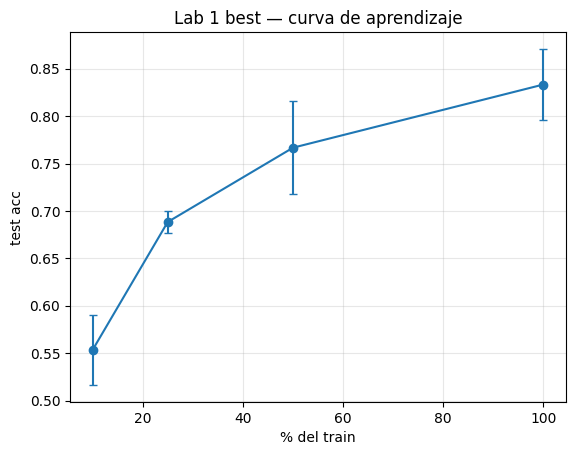

In [ ]:
FRACS = [0.10, 0.25, 0.50, 1.00]
LC_SEEDS = SEEDS[:3]
lc_rows = []
for seed in LC_SEEDS:
    split = load_or_make_split(seed); prep_s = prepare(split)
    Xtr_s, Xte_s, ytr_s, yte_s = prep_s.get_data(); gtr_s, _ = prep_s.get_groups()
    songs_tr = np.array(sorted(set(gtr_s)))
    for frac in FRACS:
        if frac < 1:
            sub, _ = train_test_split(songs_tr, train_size=frac, stratify=[GENRE_OF[s] for s in songs_tr], random_state=seed)
        else:
            sub = songs_tr
        m = gtr_s.isin(set(sub)).to_numpy()
        pipe = clone(tuned_pipes[best_lab1]).fit(Xtr_s[m], ytr_s[m])
        acc = accuracy_score(yte_s, pipe.predict(Xte_s))
        lc_rows.append(dict(model="lab1_best", seed=seed, frac=frac, n_train=int(m.sum()), test_acc=acc))
        print(f"seed {seed} | {frac:.0%} ({m.sum()} songs): {acc:.3f}")
lc = pd.DataFrame(lc_rows); lc.to_csv(OUT / "learning_curve_lab1.csv", index=False)
g = lc.groupby("frac").test_acc.agg(["mean", "std"])
plt.errorbar(g.index * 100, g["mean"], yerr=g["std"], marker="o", capsize=3); plt.xlabel("% del train"); plt.ylabel("test acc")
plt.title("Lab 1 best — Learning Curve"); plt.grid(alpha=.3); plt.show()

In summary, Pipelines are chosen with cross-validation on the training songs,  the test set is only used for the final evaluation of the two selected pipelines. With 200 test songs the standard error of an accuracy near 0.8 is about 2.8 pp, and the five-partition results above should be preferred to the seed-42 value when comparing with the CNNs.

**Next notebooks:** `multiseed_retraining` → `analysis`.